# MNIST Classification with a Neural Network Built from Scratch

This notebook follows the complete lifecycle of a handwritten-digit classifier: downloading MNIST, parsing its raw IDX files, inspecting and preparing the data, training a fully connected neural network with manually managed parameters, evaluating predictions, and saving the learned weights.

### Learning goals

- Understand the shape and structure of the MNIST dataset.
- Prepare image data for a dense neural network.
- Follow a manual forward pass, loss calculation, backpropagation, and parameter update.
- Evaluate and persist the trained parameters.

### Roadmap

1. Acquire and parse the data.
2. Inspect and preprocess the dataset.
3. Initialize and train the network.
4. Evaluate predictions and save the parameters.

## 1. Download the MNIST dataset

Kaggle Hub downloads the dataset and returns the local directory containing the raw files.

In [53]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Path to dataset files: <kagglehub-cache>\datasets\hojjatk\mnist-dataset\versions\1


## 2. Parse the raw IDX files

MNIST images and labels use a compact binary IDX format. The loader validates each file's magic number and reshapes every image into a 28 by 28 array.

In [54]:
#
# This is a sample Notebook to demonstrate how to read "MNIST Dataset"
#
import numpy as np # linear algebra
import struct
from array import array
from os.path  import join



In [55]:
#
# MNIST Data Loader Class
#
class MnistDataloader(object):
    def __init__(self, training_images_filepath,training_labels_filepath,
                 test_images_filepath, test_labels_filepath):
        self.training_images_filepath = training_images_filepath
        self.training_labels_filepath = training_labels_filepath
        self.test_images_filepath = test_images_filepath
        self.test_labels_filepath = test_labels_filepath
    
    def read_images_labels(self, images_filepath, labels_filepath):        
        labels = []
        with open(labels_filepath, 'rb') as file:
            magic, size = struct.unpack(">II", file.read(8))
            if magic != 2049:
                raise ValueError('Magic number mismatch, expected 2049, got {}'.format(magic))
            labels = array("B", file.read())        
        
        with open(images_filepath, 'rb') as file:
            magic, size, rows, cols = struct.unpack(">IIII", file.read(16))
            if magic != 2051:
                raise ValueError('Magic number mismatch, expected 2051, got {}'.format(magic))
            image_data = array("B", file.read())        
        images = []
        for i in range(size):
            images.append([0] * rows * cols)
        for i in range(size):
            img = np.array(image_data[i * rows * cols:(i + 1) * rows * cols])
            img = img.reshape(28, 28)
            images[i][:] = img            
        
        return images, labels
            
    def load_data(self):
        x_train, y_train = self.read_images_labels(self.training_images_filepath, self.training_labels_filepath)
        x_test, y_test = self.read_images_labels(self.test_images_filepath, self.test_labels_filepath)
        return (x_train, y_train),(x_test, y_test)        

## 3. Load and preview the dataset

Resolve the four dataset files, load the training and test splits, and inspect a random sample before modeling.

### Locate and load the files

In [56]:
#
# Set file paths based on added MNIST Datasets
#
input_path = path
training_images_filepath = join(input_path, 'train-images-idx3-ubyte/train-images-idx3-ubyte')
training_labels_filepath = join(input_path, 'train-labels-idx1-ubyte/train-labels-idx1-ubyte')
test_images_filepath = join(input_path, 't10k-images-idx3-ubyte/t10k-images-idx3-ubyte')
test_labels_filepath = join(input_path, 't10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte')



In [57]:
#
# Load MINST dataset
#
mnist_dataloader = MnistDataloader(training_images_filepath, training_labels_filepath, test_images_filepath, test_labels_filepath)
(x_train, y_train), (x_test, y_test) = mnist_dataloader.load_data()



### Preview random examples

The labels above the images provide a quick visual check that parsing and reshaping worked correctly.

In [58]:
#
# Verify Reading Dataset via MnistDataloader class
#
%matplotlib inline
import random
import matplotlib.pyplot as plt



In [59]:
#
# Helper function to show a list of images with their relating titles
#
def show_images(images, title_texts):
    cols = 5
    rows = int(len(images)/cols) + 1
    plt.figure(figsize=(30,20))
    index = 1    
    for x in zip(images, title_texts):        
        image = x[0]        
        title_text = x[1]
        plt.subplot(rows, cols, index)        
        plt.imshow(image, cmap=plt.cm.gray)
        if (title_text != ''):
            plt.title(title_text, fontsize = 15);        
        index += 1



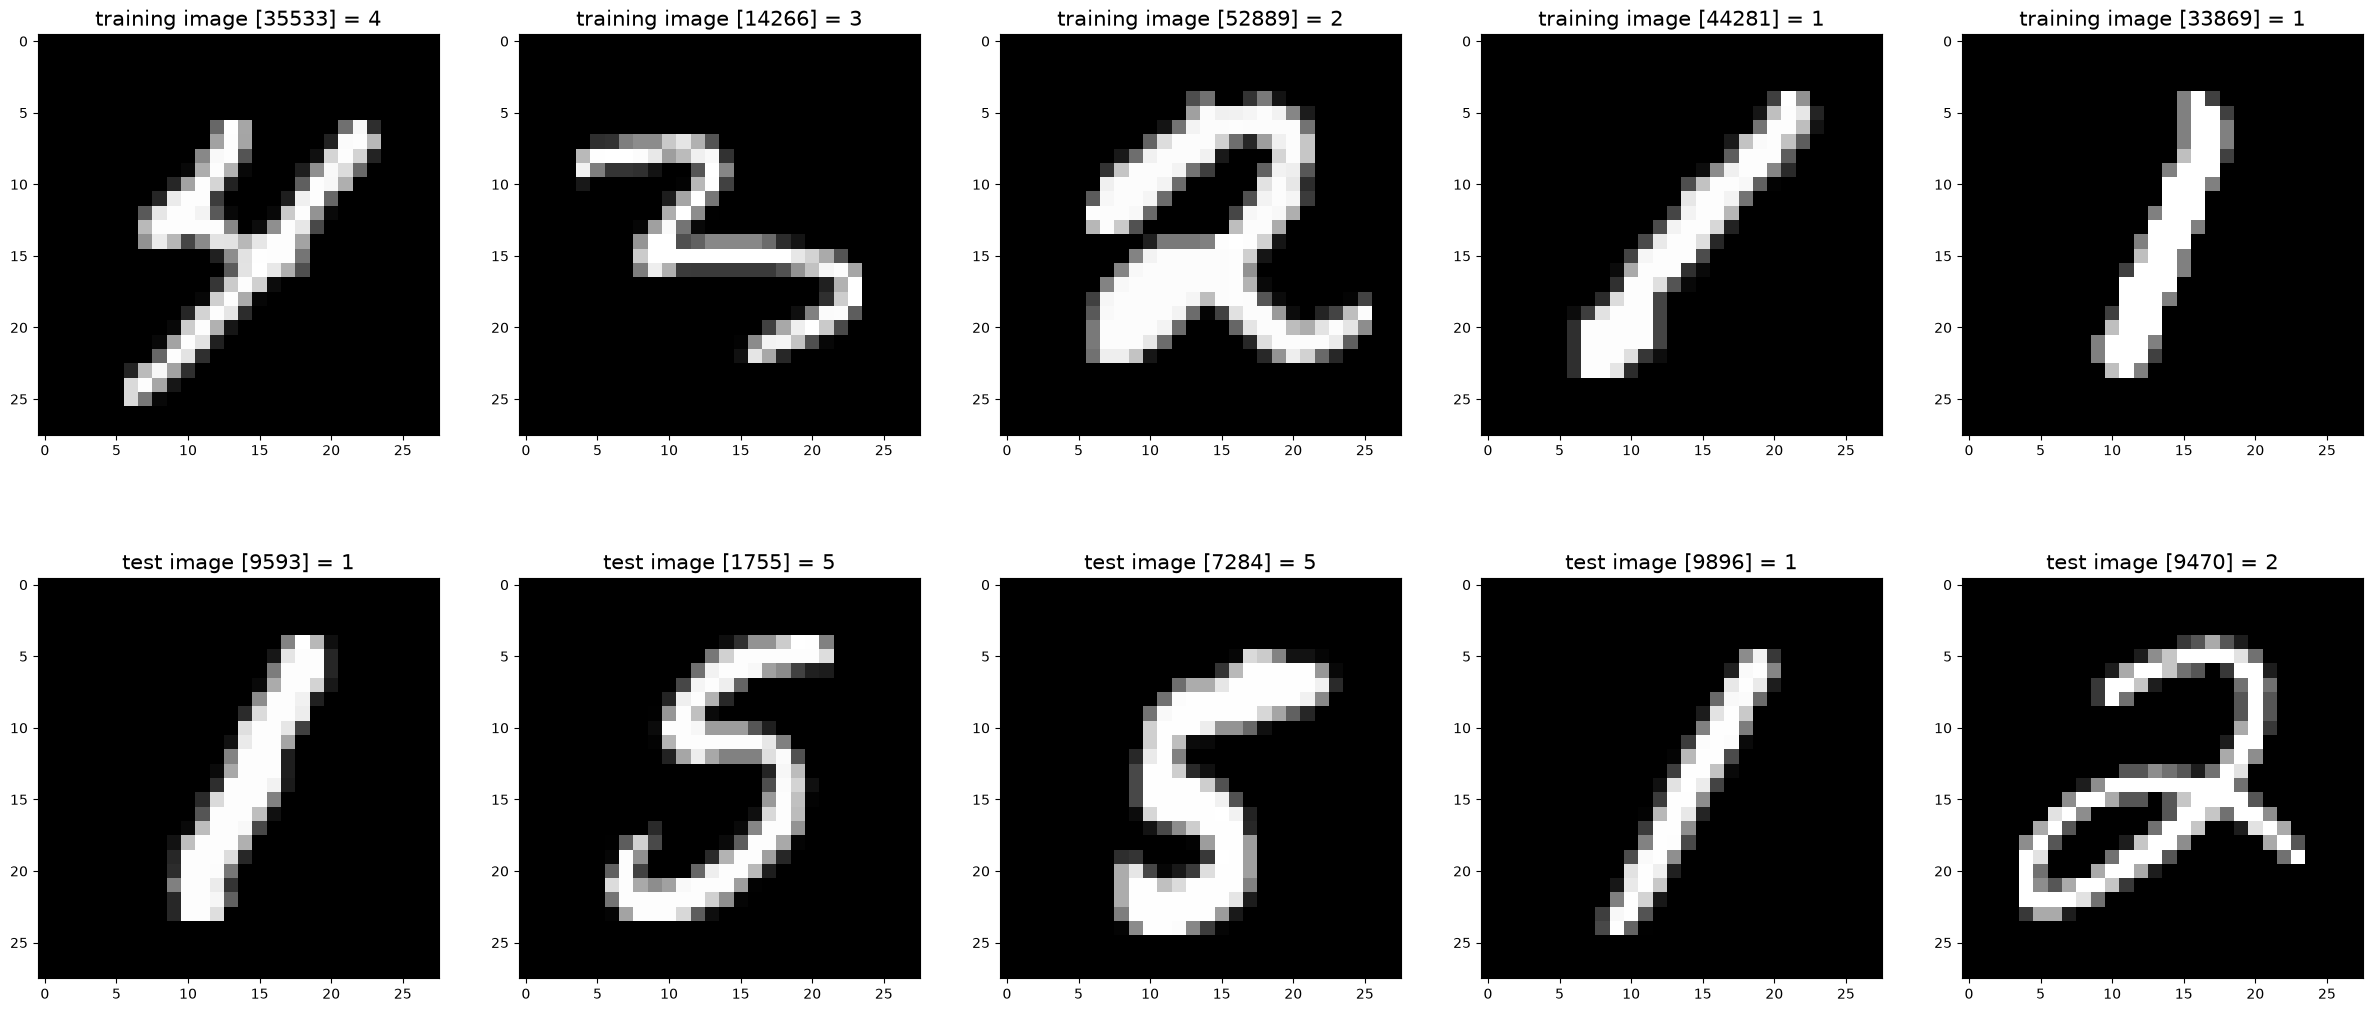

In [60]:
#
# Show some random training and test images 
#
images_2_show = []
titles_2_show = []
for i in range(0, 5):
    r = random.randint(1, 60000)
    images_2_show.append(x_train[r])
    titles_2_show.append('training image [' + str(r) + '] = ' + str(y_train[r]))    

for i in range(0, 5):
    r = random.randint(1, 10000)
    images_2_show.append(x_test[r])        
    titles_2_show.append('test image [' + str(r) + '] = ' + str(y_test[r]))    

show_images(images_2_show, titles_2_show)

## 4. Inspect the dataset dimensions

Confirm the number of examples in each split and the dimensions of an individual image.

In [61]:
training_image_count = len(x_train)
training_image_label = len(y_train)

test_image_count = len(x_test)
test_image_label = len(y_test)

print(
    f"training image: {training_image_count} \ntraining label: {training_image_label} \ntest image: {test_image_count} \ntest label: {test_image_label}"
)

training image: 60000 
training label: 60000 
test image: 10000 
test label: 10000


In [62]:
# assuming its a 2 dimensional array to represent each images

#x[row][col]

row_length = len(x_train[0]) #row
col_length = len(x_train[0][0]) # column

print(f"row: {row_length}\ncol: {col_length}")

row: 28
col: 28


Each image contains 28 by 28 pixels. Flattening those pixels produces the 784 input features used by the network.

## 5. Initialize the network parameters

The classifier uses three dense transformations: 784 to 256 features, 256 to 128 features, and 128 features to 10 digit classes. PyTorch tracks gradients directly on each weight and bias tensor.

In [63]:
import math
import torch

in_dim = 784
h1_dim = 256
h2_dim = 128
out_dim = 10



In [64]:
W1 = torch.randn(in_dim, h1_dim) * math.sqrt(2.0 / in_dim) # using He/Kaiming initialization
b1 = torch.randn(h1_dim)

W2 = torch.randn(h1_dim, h2_dim) * math.sqrt(2.0 / in_dim)
b2 = torch.randn(h2_dim)

W3 = torch.randn(h2_dim, out_dim) * math.sqrt(2.0 / in_dim)
b3 = torch.randn(out_dim)

for p in [W1, b1, W2, b2, W3, b3]:
    p.requires_grad_() # track the gradient 

## 6. Prepare tensors for training

Convert labels and images to tensors, flatten each image, scale pixel values to the 0-to-1 range, and verify the final shapes.

In [65]:
# label checking 

# Zero-copy conversion using memory buffer (faster)
y_train = np.frombuffer(y_train, dtype=np.uint8)

In [66]:
print(y_train.shape)

(60000,)


In [67]:
x_train = torch.tensor(np.asarray(x_train)).float()
y_train = torch.tensor(np.asarray(y_train))

x_test = torch.tensor(np.asarray(x_test)).float()
y_test = torch.tensor(np.asarray(y_test))

In [68]:
x_train = torch.flatten(x_train, start_dim = 1)
x_test = torch.flatten(x_test, start_dim = 1)

In [69]:
x_train = x_train.float() / 255.0
x_test = x_test.float() /255.0

In [70]:
x_train_mean = x_train.mean()
x_train_std = x_train.std()

x_train_normalized = (x_train - x_train_mean) / x_train_std
x_test_normalized = ((x_test.float() / 255.0) - x_train_mean) / x_train_std

x_train = x_train_normalized
x_test = x_test_normalized

In [71]:
print("Normalized Mean:", x_train_normalized.mean().item()) # Near 0.0
print("Normalized Std: ", x_train_normalized.std().item())  # Near 1.0

Normalized Mean: -7.05848757220906e-09
Normalized Std:  0.9999999403953552


In [72]:
print(f"x_train shape: {x_train.shape} \nx_test shape: {x_test.shape} \ny_train shape: {y_train.shape} \ny_test shape: {y_test.shape}")

x_train shape: torch.Size([60000, 784]) 
x_test shape: torch.Size([10000, 784]) 
y_train shape: torch.Size([60000]) 
y_test shape: torch.Size([10000])


## 7. Train the network

Mini-batch training performs a forward pass, computes cross-entropy loss, backpropagates gradients, and applies manual gradient-descent updates. The live chart tracks loss across batches.

In [73]:
import torch.optim as optim
import torch.nn.functional as F
from IPython.display import clear_output

batch_size = 64
epochs = 70
learning_rate = 0.001
num_samples = x_train.shape[0]

params = [W1, b1, W2, b2, W3, b3]
optimizer = optim.Adam(
    params,
    lr=learning_rate,    
    betas=(0.9, 0.999),  # Coefficients for exponential moving averages of gradients
    eps=1e-08,          # Small constant added to denominator for numerical stability
    weight_decay=1e-4   # L2 penalty coefficient for regularization
)

loss_history = []



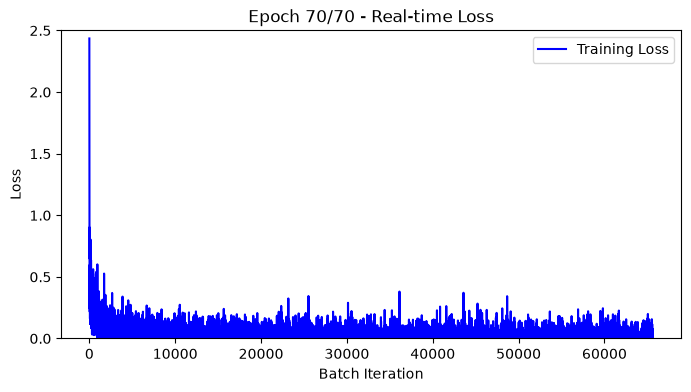

Epoch 70/70 completed.


In [74]:
for epoch in range(epochs):
    for i in range(0, num_samples, batch_size):
        # taking x amount of data for each batch
        X_batch = x_train[i : i+batch_size]
        y_batch = y_train[i : i+batch_size]

        # forward prop
        output1 = torch.relu(torch.matmul(X_batch, W1) + b1)
        output2 = torch.relu(torch.matmul(output1, W2) + b2)
        logits = torch.matmul(output2, W3) + b3


        proba = torch.nn.functional.softmax(logits, dim=-1) # convert logits to probabilities using softmax
        loss = F.cross_entropy(logits, y_batch) # calculate loss

        # Track loss value
        loss_history.append(loss.item())

        # Update plot every 10 iterations to minimize plot rendering lag
        if i % (batch_size * 10) == 0:
            clear_output(wait=True)
            plt.figure(figsize=(8, 4))
            plt.plot(loss_history, label="Training Loss", color="blue")
            plt.xlabel("Batch Iteration")
            plt.ylabel("Loss")
            plt.ylim(0.0, 2.5)
            plt.title(f"Epoch {epoch + 1}/{epochs} - Real-time Loss")
            plt.legend()
            plt.show()

        # Backward pass and parameter update
        optimizer.zero_grad()  # 1. Reset stored gradients to zero
        loss.backward()        # 2. Compute gradients for all params
        optimizer.step()       # 3. Update parameters using Adam logic

    print(f"Epoch {epoch + 1}/{epochs} completed.")



> **Preserved-output note:** The recorded training run was interrupted while Matplotlib rendered the live loss chart. Later evaluation outputs are retained from the notebook's existing in-memory state.

## 8. Evaluate on the test set

Run a forward pass without gradient tracking and select the class with the largest logit for each test image.

In [75]:
with torch.no_grad():
    output1 = torch.relu(torch.matmul(x_test, W1) + b1)
    output2 = torch.relu(torch.matmul(output1, W2) + b2)
    logits = torch.matmul(output2, W3) + b3
    labels = torch.argmax(logits, dim=-1)

### Classification metrics

Precision, recall, and F1-score show how performance varies across the ten digit classes.

In [76]:
from sklearn.metrics import classification_report

print(classification_report(y_test, labels, digits=4))

              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000       980
           1     0.1135    1.0000    0.2039      1135
           2     0.0000    0.0000    0.0000      1032
           3     0.0000    0.0000    0.0000      1010
           4     0.0000    0.0000    0.0000       982
           5     0.0000    0.0000    0.0000       892
           6     0.0000    0.0000    0.0000       958
           7     0.0000    0.0000    0.0000      1028
           8     0.0000    0.0000    0.0000       974
           9     0.0000    0.0000    0.0000      1009

    accuracy                         0.1135     10000
   macro avg     0.0114    0.1000    0.0204     10000
weighted avg     0.0129    0.1135    0.0231     10000



c:\Users\coder\OneDrive\Desktop\mnist handwritten dataset classification nn\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\coder\OneDrive\Desktop\mnist handwritten dataset classification nn\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\coder\OneDrive\Desktop\mnist handwritten dataset classification nn\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted

### Confusion matrix

The confusion matrix makes common misclassifications visible by comparing true and predicted labels.

In [77]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Get predictions from raw logits (disable gradient tracking)
with torch.no_grad():
    output1 = torch.relu(torch.matmul(x_test, W1) + b1)
    output2 = torch.relu(torch.matmul(output1, W2) + b2)
    logits = torch.matmul(output2, W3) + b3
    predicted_labels = torch.argmax(logits, dim=-1)



In [78]:
# 2. Convert PyTorch tensors to NumPy arrays
y_true = y_test.cpu().numpy()
y_pred = predicted_labels.cpu().numpy()



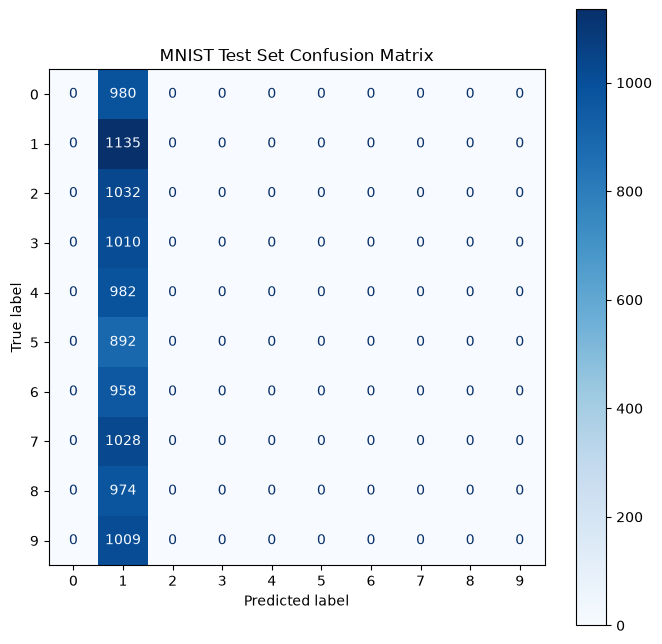

In [79]:
# 3. Generate and plot the confusion matrix
fig, ax = plt.subplots(figsize=(8, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=[str(i) for i in range(10)], # Class labels 0-9
    cmap="Blues",                                # Color map
    values_format="d",                           # Display counts as integers
    ax=ax
)

plt.title("MNIST Test Set Confusion Matrix")
plt.show()

## 9. Save and reload the learned parameters

Store the six parameter tensors in a state dictionary, reload them from disk, and verify the shape of the first weight matrix.

In [80]:
# Pack weights and biases into a dictionary
state_dict = {
    'W1': W1, 'b1': b1,
    'W2': W2, 'b2': b2,
    'W3': W3, 'b3': b3
}

# Save the dictionary to disk
torch.save(state_dict, 'model_weights.pth')

In [81]:
# Load dictionary from disk
checkpoint = torch.load('model_weights.pth')

# Extract individual tensors
W1 = checkpoint['W1']
b1 = checkpoint['b1']
W2 = checkpoint['W2']
b2 = checkpoint['b2']
W3 = checkpoint['W3']
b3 = checkpoint['b3']

In [82]:
print(W1.shape)

torch.Size([784, 256])
